데이터 다운 사이트 : https://www.kaggle.com/c/carvana-image-masking-challenge

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import ml_collections
import matplotlib.pyplot as plt
import cv2
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
from src.utils.custom_dataset import * # Load CustomDataset Class 
from src.utils.generate_operating_condition import *
from src.utils.preprocess import *
from src.utils.config import *

# cuDNN error: CUDNN_STATUS_MAPPING_ERROR 에러...해결코드
torch.backends.cudnn.enabled = False

### 0. 데이터확인

In [2]:
data_path = "dataset/preprocessed/"
data_lst = os.listdir(data_path)
ux_lst = []
uy_lst = []
p_lst = []
boundary_lst = []
for name in tqdm(data_lst):
    df = pd.read_csv(data_path+name)
    boundary_lst.append(df["boundary"])            
    ux_lst.append(df["ux"].values)
    uy_lst.append(df["uy"].values)
    p_lst.append(df["p"].values)

boundary_data = np.array(boundary_lst).astype('float32')
ux_data = np.array(ux_lst).astype('float32')
uy_data = np.array(uy_lst).astype('float32')
p_data = np.array(p_lst).astype('float32')

dataset_config = get_dataset_config(ux_data,uy_data,p_data)
xsize = dataset_config.xsize
ysize = dataset_config.ysize
ux_max = dataset_config.ux_max
uy_max = dataset_config.uy_max
p_max = dataset_config.p_max

boundary_data = boundary_data.reshape(-1,xsize,ysize)
ux_data = ux_data.reshape(-1,xsize,ysize)
ux_data /= ux_max
uy_data = uy_data.reshape(-1,xsize,ysize)
uy_data /= uy_max
p_data = p_data.reshape(-1,xsize,ysize)
p_data /= p_max

  0%|          | 0/550 [00:00<?, ?it/s]

100%|██████████| 550/550 [00:05<00:00, 95.07it/s]


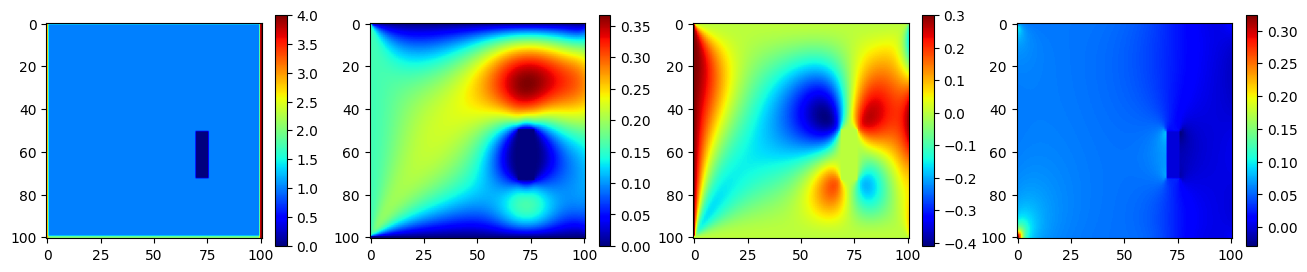

In [3]:
plot_idx = 0 
plt.figure(figsize=[16,3])

plt.subplot(1,4,1)
plt.imshow(boundary_data[plot_idx],cmap='jet')
plt.colorbar()
plt.subplot(1,4,2)
plt.imshow(ux_data[plot_idx],cmap='jet')
plt.colorbar()
plt.subplot(1,4,3)
plt.imshow(uy_data[plot_idx],cmap='jet')
plt.colorbar()
plt.subplot(1,4,4)
plt.imshow(p_data[plot_idx],cmap='jet')
plt.colorbar()

### 1. 데이터세트 로드

In [4]:
import torchvision.transforms as transforms

dataset = CustomDatasetUNet(transform=transforms.Compose([transforms.ToTensor()]),
                            target_transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 550/550 [00:05<00:00, 96.28it/s] 


In [5]:
from torch.utils.data import random_split

dataset_size = len(dataset)
train_size = int(dataset_size * 0.8)
validation_size = int(dataset_size * 0.1)
test_size = dataset_size - train_size - validation_size

train_dataset, validation_dataset, test_dataset = random_split(dataset,[train_size,validation_size,test_size],
                                                               generator=torch.Generator().manual_seed(42))
print(f"Training Data Size : {len(train_dataset)}")
print(f"Validation Data Size : {len(validation_dataset)}")
print(f"Testing Data Size : {len(test_dataset)}")

Training Data Size : 440
Validation Data Size : 55
Testing Data Size : 55


In [6]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(train_dataset, batch_size=4, shuffle=True)
validation_dataloader = DataLoader(validation_dataset, batch_size=4, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=4, shuffle=True)

In [23]:
for a,b,c,d,e,f in train_dataloader:
    print(a.shape)
    print(b.shape)
    print(c.shape)
    print(d.shape)
    print(e.shape)
    print(f.shape)
    # plt.figure(figsize=[12,9])
    # for idx in range(4):
    #     plt.subplot(1,4,idx+1)
    #     plt.imshow(a[idx][0])
    break

torch.Size([4, 1, 101, 101])
torch.Size([4, 5])
torch.Size([4, 5])
torch.Size([4, 1, 101, 101])
torch.Size([4, 1, 101, 101])
torch.Size([4, 1, 101, 101])


### 2. 모델 로드

In [13]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

from src.model.unet_model import *
model = UNet().to(device)

### 3. 학습/검증 수행

In [9]:
def train_loop(dataloader,model,loss_fn,optimizer):
    
    # 입력 데이터세트의 총 길이 
    size = len(dataloader.dataset) # 320

    # 배치 총 개수 (320/4 = 80) 
    num_batches = len(dataloader)
    
    # loss 초기화
    train_loss = 0

    # train_loop 
    for batch, (bdr,st,sv,ux,uy,p) in enumerate(tqdm(dataloader)): 
        
        # 타입 & device 변환
        bdr = bdr.type(torch.float32).to(device)
        st = st.type(torch.int32).to(device)
        sv = sv.type(torch.float32).to(device)
        ux = ux.type(torch.float32).to(device)
        uy = uy.type(torch.float32).to(device)
        p = p.type(torch.float32).to(device)

        X = [bdr,st,sv]
        y = torch.concat([ux,uy,p],axis=1)
        
        # 모델 예측
        pred = model(X)

        # Loss 계산
        loss = loss_fn(pred,y)
    
        # Backpropagation
        optimizer.zero_grad() # 이전 루프에서 각 파라미터들에 저장된 .grad를 초기화
        loss.backward() # 각 파라미터들의 .grad값에 변화정도가 저장이 됨.
        optimizer.step() # 최적화함수에 맞게, 각 파라미터 업데이트

        # LOSS 
        train_loss += loss.item() # item()을 통해, 변수에서 값만 가져옴

    train_loss /= num_batches
    print(f"Train loss: {train_loss:>8f} \n")
    
    return train_loss

def validation_loop(dataloader,model,loss_fn):

    # 입력 데이터세트의 총 길이
    size = len(dataloader.dataset) # 40
    
    # 배치 총 개수 (40/4 = 10)
    num_batches = len(dataloader)

    # loss 초기화
    validation_loss = 0

    # 테스트 단계이므로 gradient 옵션 해제
    with torch.no_grad():
        for bdr,st,sv,ux,uy,p in tqdm(dataloader):
            
            # 타입 & device 변환
            bdr = bdr.type(torch.float32).to(device)
            st = st.type(torch.int32).to(device)
            sv = sv.type(torch.float32).to(device)
            ux = ux.type(torch.float32).to(device)
            uy = uy.type(torch.float32).to(device)
            p = p.type(torch.float32).to(device)

            X = [bdr,st,sv]
            y = torch.concat([ux,uy,p],axis=1)
            
            # 모델 예측
            pred = model(X)
            
            # Loss 계산
            loss = loss_fn(pred,y)

            # LOSS 
            validation_loss += loss.item() # item()을 통해, 변수에서 값만 가져옴
    
    validation_loss /= num_batches
    
    print(f"Validation loss: {validation_loss:>8f} \n")

    return validation_loss

In [10]:
learning_rate = 1e-3
epochs = 200
loss_fn = torch.nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(),lr=learning_rate)

train_loss_all = []
validation_loss_all = []

for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loss = train_loop(train_dataloader, model, loss_fn, optimizer)
    train_loss_all.append(train_loss)
    validation_loss = validation_loop(validation_dataloader, model, loss_fn)
    validation_loss_all.append(validation_loss)
print("학습완료")

Epoch 1
-------------------------------


100%|██████████| 110/110 [00:04<00:00, 26.74it/s]


Train loss: 0.071555 



100%|██████████| 14/14 [00:00<00:00, 164.33it/s]


Validation loss: 0.057278 

Epoch 2
-------------------------------


...

Validation loss: 0.006691 

Epoch 200
-------------------------------


100%|██████████| 110/110 [00:01<00:00, 59.85it/s]


Train loss: 0.006999 



100%|██████████| 14/14 [00:00<00:00, 194.44it/s]

Validation loss: 0.009308 

학습완료


결과저장 & 결과확인

In [11]:
TEST_NUM = 1
model_name = "UNet"
save_model_name = f'checkpoints/{model_name}_CFD_test{TEST_NUM}.pth'
train_log_name = f'logs/{model_name}_test{TEST_NUM}_train_loss.npy'
validation_log_name = f'logs/{model_name}_test{TEST_NUM}_validation_loss.npy' 

if os.path.isfile(save_model_name):
    print("해당 테스트넘버는 학습된 파일이 존재합니다.")
    print("======= 학습된 가중치를 불러옵니다. =======")
    model.load_state_dict(torch.load(save_model_name))
else:
    torch.save(model.state_dict(),save_model_name)

if os.path.isfile(train_log_name):
    print("해당 테스트넘버는 로그 파일이 존재합니다.")
    print("===== 저장된 로그파일을 불러옵니다. =====")
    train_loss_all_arr = np.load(train_log_name)
else:
    train_loss_all_arr = np.array(train_loss_all)
    np.save(train_log_name,train_loss_all_arr)

if os.path.isfile(validation_log_name):
    print("해당 테스트넘버는 로그 파일이 존재합니다.")
    print("===== 저장된 로그파일을 불러옵니다. =====")
    validation_loss_all_arr = np.load(validation_log_name)
else:
    validation_loss_all_arr = np.array(validation_loss_all)
    np.save(validation_log_name,validation_loss_all_arr)

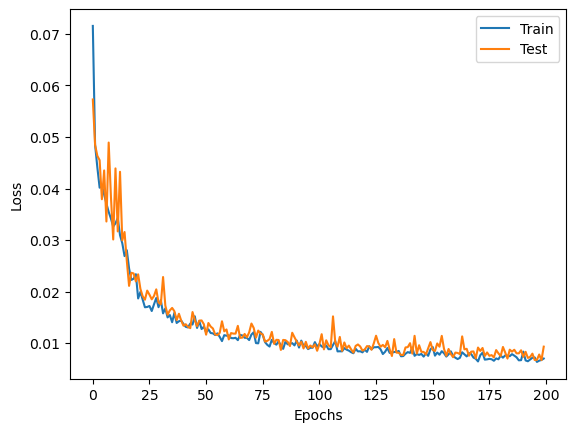

In [12]:
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.plot(train_loss_all_arr,label='Train')
plt.plot(validation_loss_all_arr,label='Test')
plt.legend()

### 4. 테스트

In [13]:
test_loss = 0
num_batches = len(test_dataloader)
print(num_batches)
bdr_lst = []
label_lst = []
pred_lst = []


for bdr,st,sv,ux,uy,p in tqdm(test_dataloader):

    # 타입 & device 변환
    bdr = bdr.type(torch.float32).to(device)
    st = st.type(torch.int32).to(device)
    sv = sv.type(torch.float32).to(device)
    ux = ux.type(torch.float32).to(device)
    uy = uy.type(torch.float32).to(device)
    p = p.type(torch.float32).to(device)

    X = [bdr,st,sv]
    y = torch.concat([ux,uy,p],axis=1)
    
    # 모델 예측
    pred = model(X)
    
    bdr = bdr.to('cpu')
    st = st.to('cpu')
    sv = sv.to('cpu')
    y = y.to('cpu')
    pred = pred.to('cpu')

    bdr_lst.append(bdr)
    label_lst.append(y)
    pred_lst.append(pred)

    # Loss 계산
    loss = loss_fn(pred,y)

    # LOSS 
    test_loss += loss.item() # item()을 통해, 변수에서 값만 가져옴

14


100%|██████████| 14/14 [00:00<00:00, 49.65it/s]


In [14]:
len(bdr_lst),len(label_lst),len(pred_lst)

(14, 14, 14)

In [15]:
bdr_lst[0].shape,label_lst[0].shape,pred_lst[0].shape

(torch.Size([4, 1, 101, 101]),
 torch.Size([4, 3, 101, 101]),
 torch.Size([4, 3, 101, 101]))

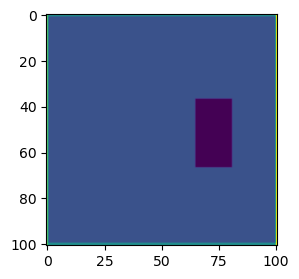

In [16]:
batch_num = 3

plt.figure(figsize=[8,3])
plt.imshow(bdr_lst[0][batch_num][0].detach().numpy())

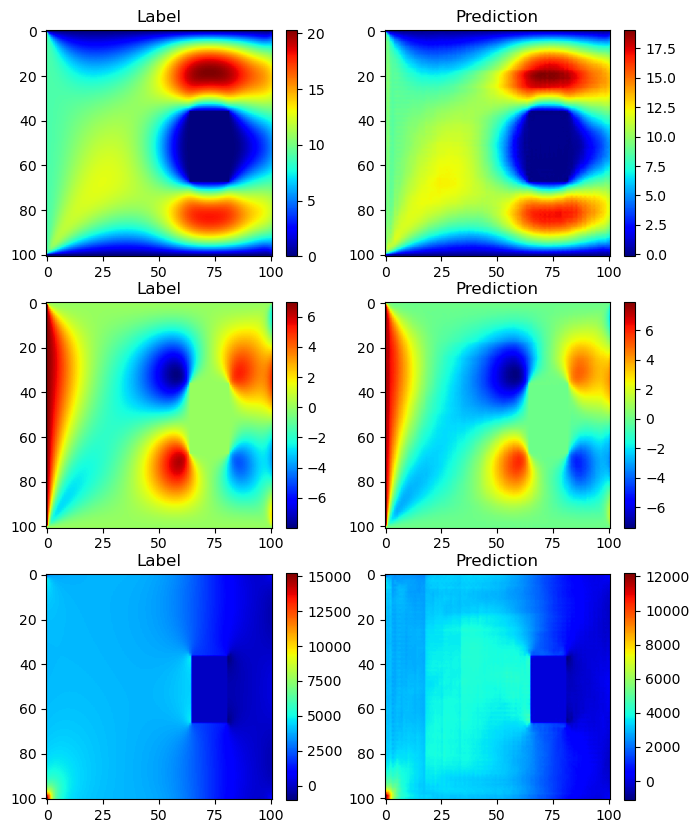

In [17]:
plot_dic = {0:dataset_config.ux_max,1:dataset_config.uy_max,2:dataset_config.p_max}
plot_subject = 0
plt.figure(figsize=[8,10])
for idx in [1,3,5]:
    plt.subplot(3,2,idx)
    plt.imshow(label_lst[0][batch_num][plot_subject].detach().numpy()*plot_dic[plot_subject],cmap='jet')
    plt.title('Label')
    plt.colorbar()
    plt.subplot(3,2,idx+1)
    plt.imshow(pred_lst[0][batch_num][plot_subject].detach().numpy()*plot_dic[plot_subject],cmap='jet')
    plt.title('Prediction')
    plt.colorbar()
    plot_subject += 1